In [25]:
import os
from scipy.optimize import curve_fit

from data_class import Data
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt 

runs = ["A", "E", "F"]

files = [f"2026-10-15_{r}_e.csv" for r in runs]

dfs = [Data(file).data for file in files]

result = pd.concat(dfs, ignore_index=True)

cam_pos = np.arange(2.5, 7.5, 0.5)



f:\Data\2026\*\*\*\2026-10-15_A_e.csv
f:\Data\2026\*\*\*\2026-10-15_E_e.csv
f:\Data\2026\*\*\*\2026-10-15_F_e.csv


In [3]:
def x2(x, a, b, c):
    return a*(x-b)**2 + c

In [4]:
data_avg = [(run["G.dy"] + run["G.dx"])/2 for run in dfs]
data_x = [run["G.dx"] for run in dfs]
data_y = [run["G.dy"] for run in dfs]

colors = ["hotpink", "cornflowerblue", "yellowgreen"]
detunings = [135, 132, 138]

Text(0, 0.5, 'Gaussian fit y widths')

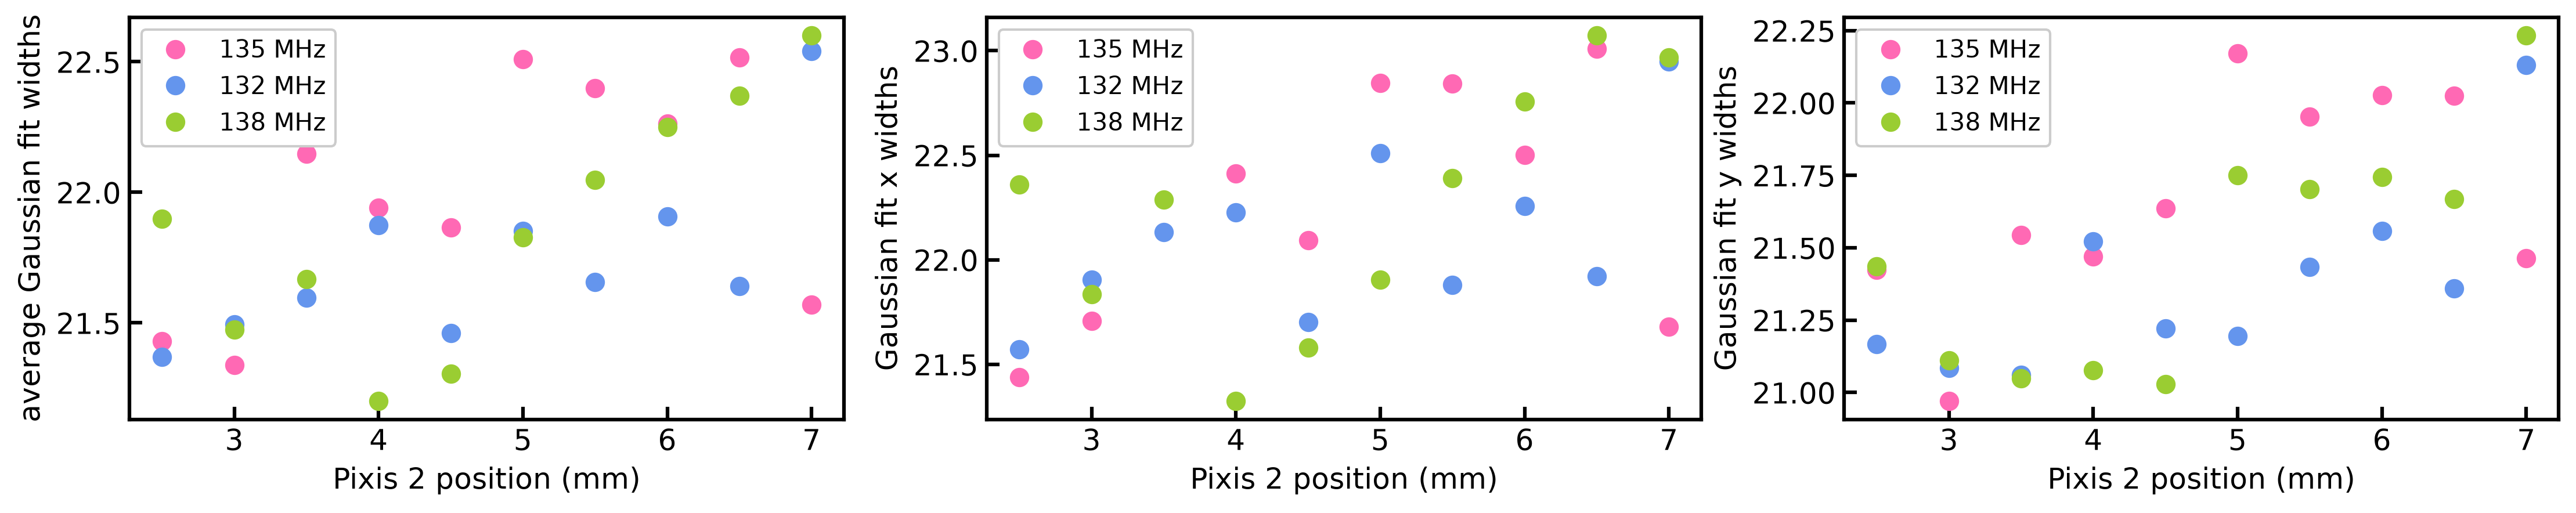

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(18, 3))
xfine = np.linspace(2.5, 7, 100)

for i in range(len(runs)):
    axs[0].plot(cam_pos, data_avg[i], label=f"{detunings[i]} MHz", color=colors[i])
    axs[1].plot(cam_pos, data_x[i], label=f"{detunings[i]} MHz", color=colors[i])
    axs[2].plot(cam_pos, data_y[i], label=f"{detunings[i]} MHz", color=colors[i])

for ax in axs:
    ax.set_xlabel("Pixis 2 position (mm)")
    ax.legend()

axs[0].set_ylabel("average Gaussian fit widths")
axs[1].set_ylabel("Gaussian fit x widths")
axs[2].set_ylabel("Gaussian fit y widths")

In [197]:
runs_low = ["G", "H", "I"]

files = [f"2026-10-15_{r}_e.csv" for r in runs_low]

dfs_low = [Data(file).data for file in files]

cam_pos_low = np.arange(0.5, 4.5, 0.5)

f:\Data\2026\*\*\*\2026-10-15_G_e.csv
f:\Data\2026\*\*\*\2026-10-15_H_e.csv
f:\Data\2026\*\*\*\2026-10-15_I_e.csv


In [214]:
data_avg_low = [(run["G.dy"] + run["G.dx"])/2 for run in dfs_low]
data_x_low = [run["G.dx"] for run in dfs_low]
data_y_low = [run["G.dy"] for run in dfs_low]

In [215]:
def line(x, m, b):
    return m*x + b

Text(0, 0.5, 'Gaussian fit y widths')

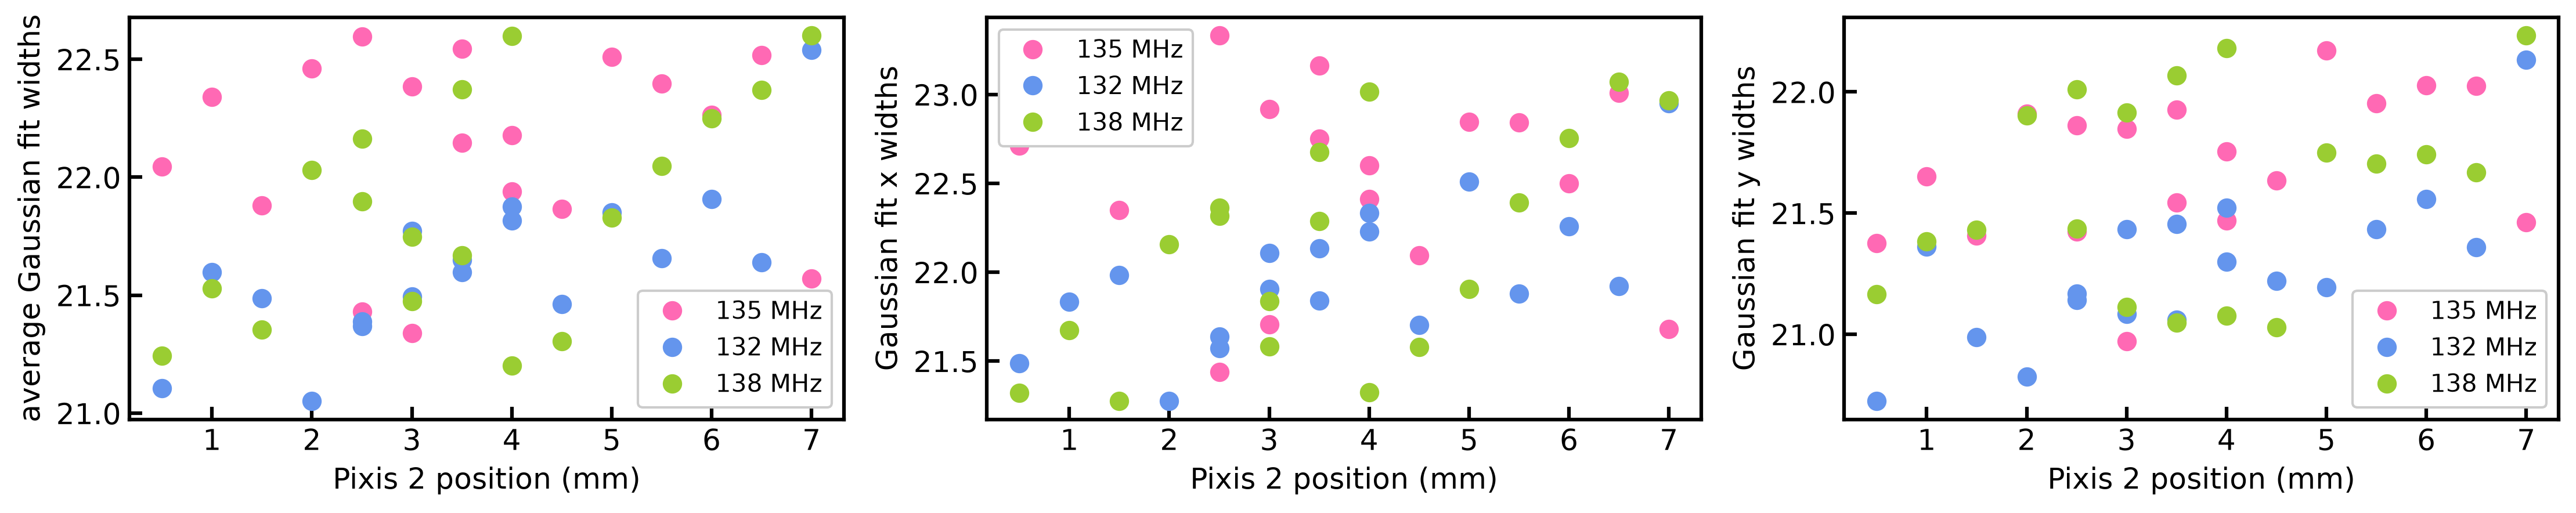

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(18, 3))
xfine = np.linspace(0.5, 7, 100)

for i in range(len(runs_low)):

    axs[0].plot(cam_pos_low, data_avg_low[i][1:], label=f"{detunings[i]} MHz", color=colors[i])
    axs[1].plot(cam_pos_low, data_x_low[i][1:], label=f"{detunings[i]} MHz", color=colors[i])
    axs[2].plot(cam_pos_low, data_y_low[i][1:], label=f"{detunings[i]} MHz", color=colors[i])

    axs[0].plot(cam_pos, data_avg[i],color=colors[i])
    axs[1].plot(cam_pos, data_x[i], color=colors[i])
    axs[2].plot(cam_pos, data_y[i], color=colors[i])

for ax in axs:
    ax.set_xlabel("Pixis 2 position (mm)")
    ax.legend()

axs[0].set_ylabel("average Gaussian fit widths")
axs[1].set_ylabel("Gaussian fit x widths")
axs[2].set_ylabel("Gaussian fit y widths")

In [252]:
runs = ["J", "L"]

files = [f"2026-10-15_{r}_e.csv" for r in runs]

dfs = [Data(file).data for file in files]

colors = ["hotpink", "cornflowerblue", "yellowgreen"]
detunings = [138, 132]

f:\Data\2026\*\*\*\2026-10-15_J_e.csv
f:\Data\2026\*\*\*\2026-10-15_L_e.csv


In [253]:
dx = [np.average(np.reshape(d["G.dx"], ( -1, 5 )), axis=-1) for d in dfs]
dy = [np.average(np.reshape(d["G.dy"], ( -1, 5 )), axis=-1) for d in dfs]
d = [(dx[i]+dy[i])/2 for i in range(len(dx))]

In [261]:
xfine = np.linspace(0, 9, 100)
xs = np.arange(0, 10)

def x2(x, a, b, c):
    return a*(x-b)**2 + c

In [ ]:
Mdf = Data(f"2026-10-15_M_e.csv")

Mdx = np.average(Mdf["G.dx"])
Mdy = np.average(Mdf["G.dy"])
Md = (dx+dy)/2


Text(0, 0.5, 'Gaussian fit y widths')

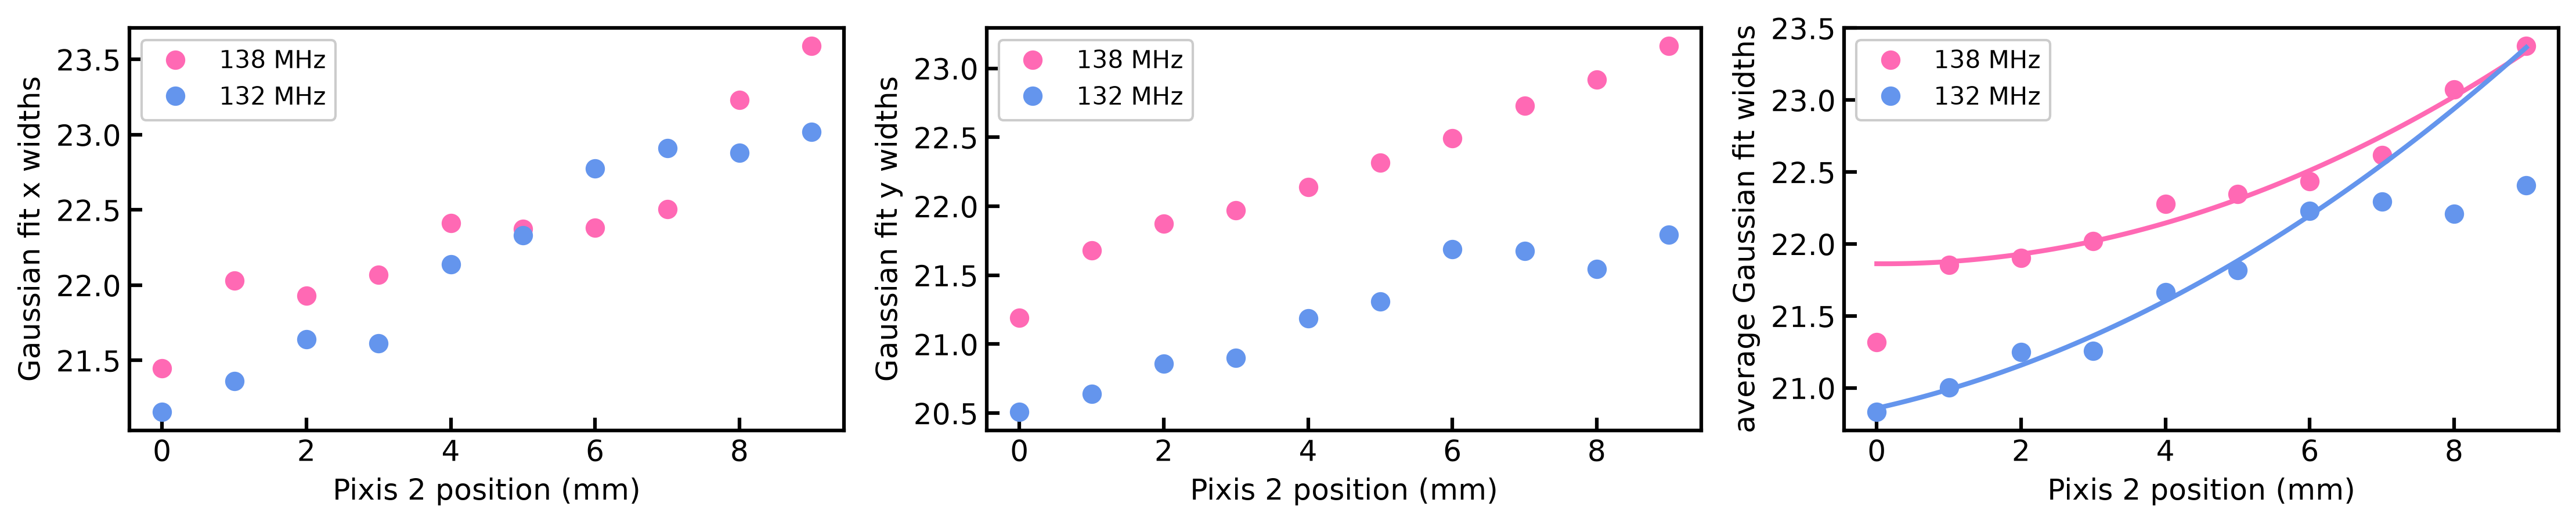

In [264]:
fig, axs = plt.subplots(1, 3, figsize=(18, 3))

for i in range(len(runs)):
    axs[0].plot(dx[i], color= colors[i], label=f"{detunings[i]} MHz")
    axs[1].plot(dy[i], color= colors[i], label=f"{detunings[i]} MHz")
    axs[2].plot(d[i], color= colors[i], label=f"{detunings[i]} MHz")

    if i==0:
        x = xs[1:]
        y = d[i][1:]
    else:
        x=xs[:-3]
        y = d[i][:-3]

    popts, __ = curve_fit(x2, x, y, p0=[0.5, -1, 21], bounds=((0, -np.inf, 0), (np.inf, np.inf, np.inf)))
    axs[2].plot(xfine, x2(xfine, *popts), color=colors[i], ls="-", marker="")

for ax in axs:
    ax.set_xlabel("Pixis 2 position (mm)")
    ax.legend()

axs[2].set_ylabel("average Gaussian fit widths")
axs[0].set_ylabel("Gaussian fit x widths")
axs[1].set_ylabel("Gaussian fit y widths")

In [22]:
df_z = Data("2026-10-19_C_e.csv").data

# Z position: (first image, last image), inclusive
z_map = {0: (0, 3),
         3: (5, 9),
         6: (10, 14),
         9: (15, 18)}

zs = np.array(list(z_map.keys()))
dx_z = np.array([df_z["G.dx"][df_z["cycle"].between(lo, hi)].mean() for lo, hi in z_map.values()])
dy_z = np.array([df_z["G.dy"][df_z["cycle"].between(lo, hi)].mean() for lo, hi in z_map.values()])
d_z = (dx_z + dy_z)/2

edx_z = np.array([df_z["G.dx"][df_z["cycle"].between(lo, hi)].std() for lo, hi in z_map.values()])
edy_z = np.array([df_z["G.dy"][df_z["cycle"].between(lo, hi)].std() for lo, hi in z_map.values()])
ed_z = np.sqrt(dx_z**2 + dy_z**2)

f:\Data\2026\*\*\*\2026-10-19_C_e.csv


Text(0, 0.5, 'Gaussian fit y widths')

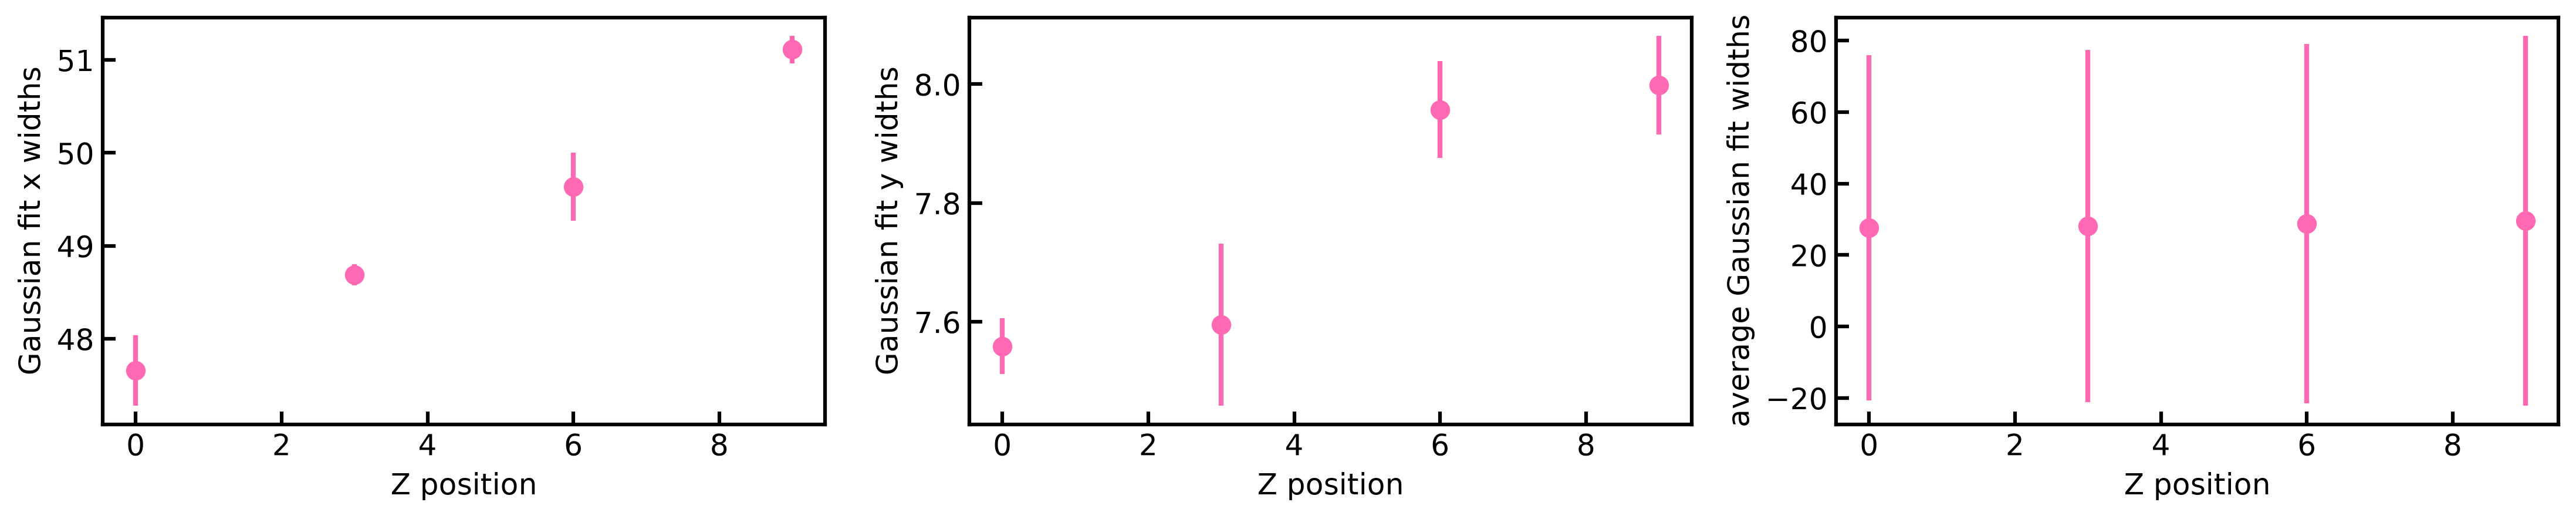

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(18, 3))

axs[0].errorbar(zs, dx_z, edx_z, color=colors[0])
axs[1].errorbar(zs, dy_z, edy_z, color=colors[0])
axs[2].errorbar(zs, d_z, ed_z, color=colors[0])

for ax in axs:
    ax.set_xlabel("Z position")

axs[2].set_ylabel("average Gaussian fit widths")
axs[0].set_ylabel("Gaussian fit x widths")
axs[1].set_ylabel("Gaussian fit y widths")

In [53]:
dfs.columns

Index(['cycle', 'imgfiles', 'setfiles', 'skip', 'roi.at_med', 'roi.ref_mean',
       'roi.ref_var', 'roi.ref_max', 'roi.ref_med', 'roi.bg_mean',
       'roi.bg_var', 'roi.bg_max', 'roi.OD_mean', 'roi.OD_max', 'roi.OD_sum',
       'roi.OD_bg', 'roi.ODCoMx', 'roi.ODCoMy', 'roi.OD_RMSx', 'roi.OD_RMSy',
       'roi.OD_tilt', 'ROIsum', 'odperatom', 'Ldx', 'Ldy', 'x0', 'y0', 'La',
       'Lb', 'q', 'eLdx', 'eLdy', 'ex0', 'ey0', 'eLa', 'eLb', 'eq',
       'Li.ninteg', 'Li.nfit', 'eLi.nfit', 'Li.Tf_n', 'Li.ToTF', 'Li.Tfx',
       'Li.Tfy', 'Li.Tx', 'Li.Ty', 'EF', 'TFcalc', 'ToTFCalc', 'EFkHz', 'psd',
       'G.dx', 'G.dy', 'G.x0', 'G.y0', 'G.a', 'G.b', 'eG.dx', 'eG.dy', 'eG.x0',
       'eG.y0', 'eG.a', 'eG.b', 'G.nfit', 'G.N', 'G.Tf_n', 'G.Tx_Tfn',
       'G.Ty_Tfn', 'G.Tx', 'G.Ty', 'GToTFCalc', 'OD_peak'],
      dtype='str')

In [54]:
dfs = Data(f"2026-10-15_N_e.csv").data
cam_pos = np.arange(0, 10, 1)

ToTF = np.average(np.reshape(dfs["Li.ToTF"], ( -1, 5 )), axis=-1)
eToTF = np.std(np.reshape(dfs["Li.ToTF"], ( -1, 5 )), axis=-1)

N = np.average(np.reshape(dfs["Li.nfit"], ( -1, 5 )), axis=-1)
eN = np.std(np.reshape(dfs["Li.nfit"], ( -1, 5 )), axis=-1)

f:\Data\2026\*\*\*\2026-10-15_N_e.csv


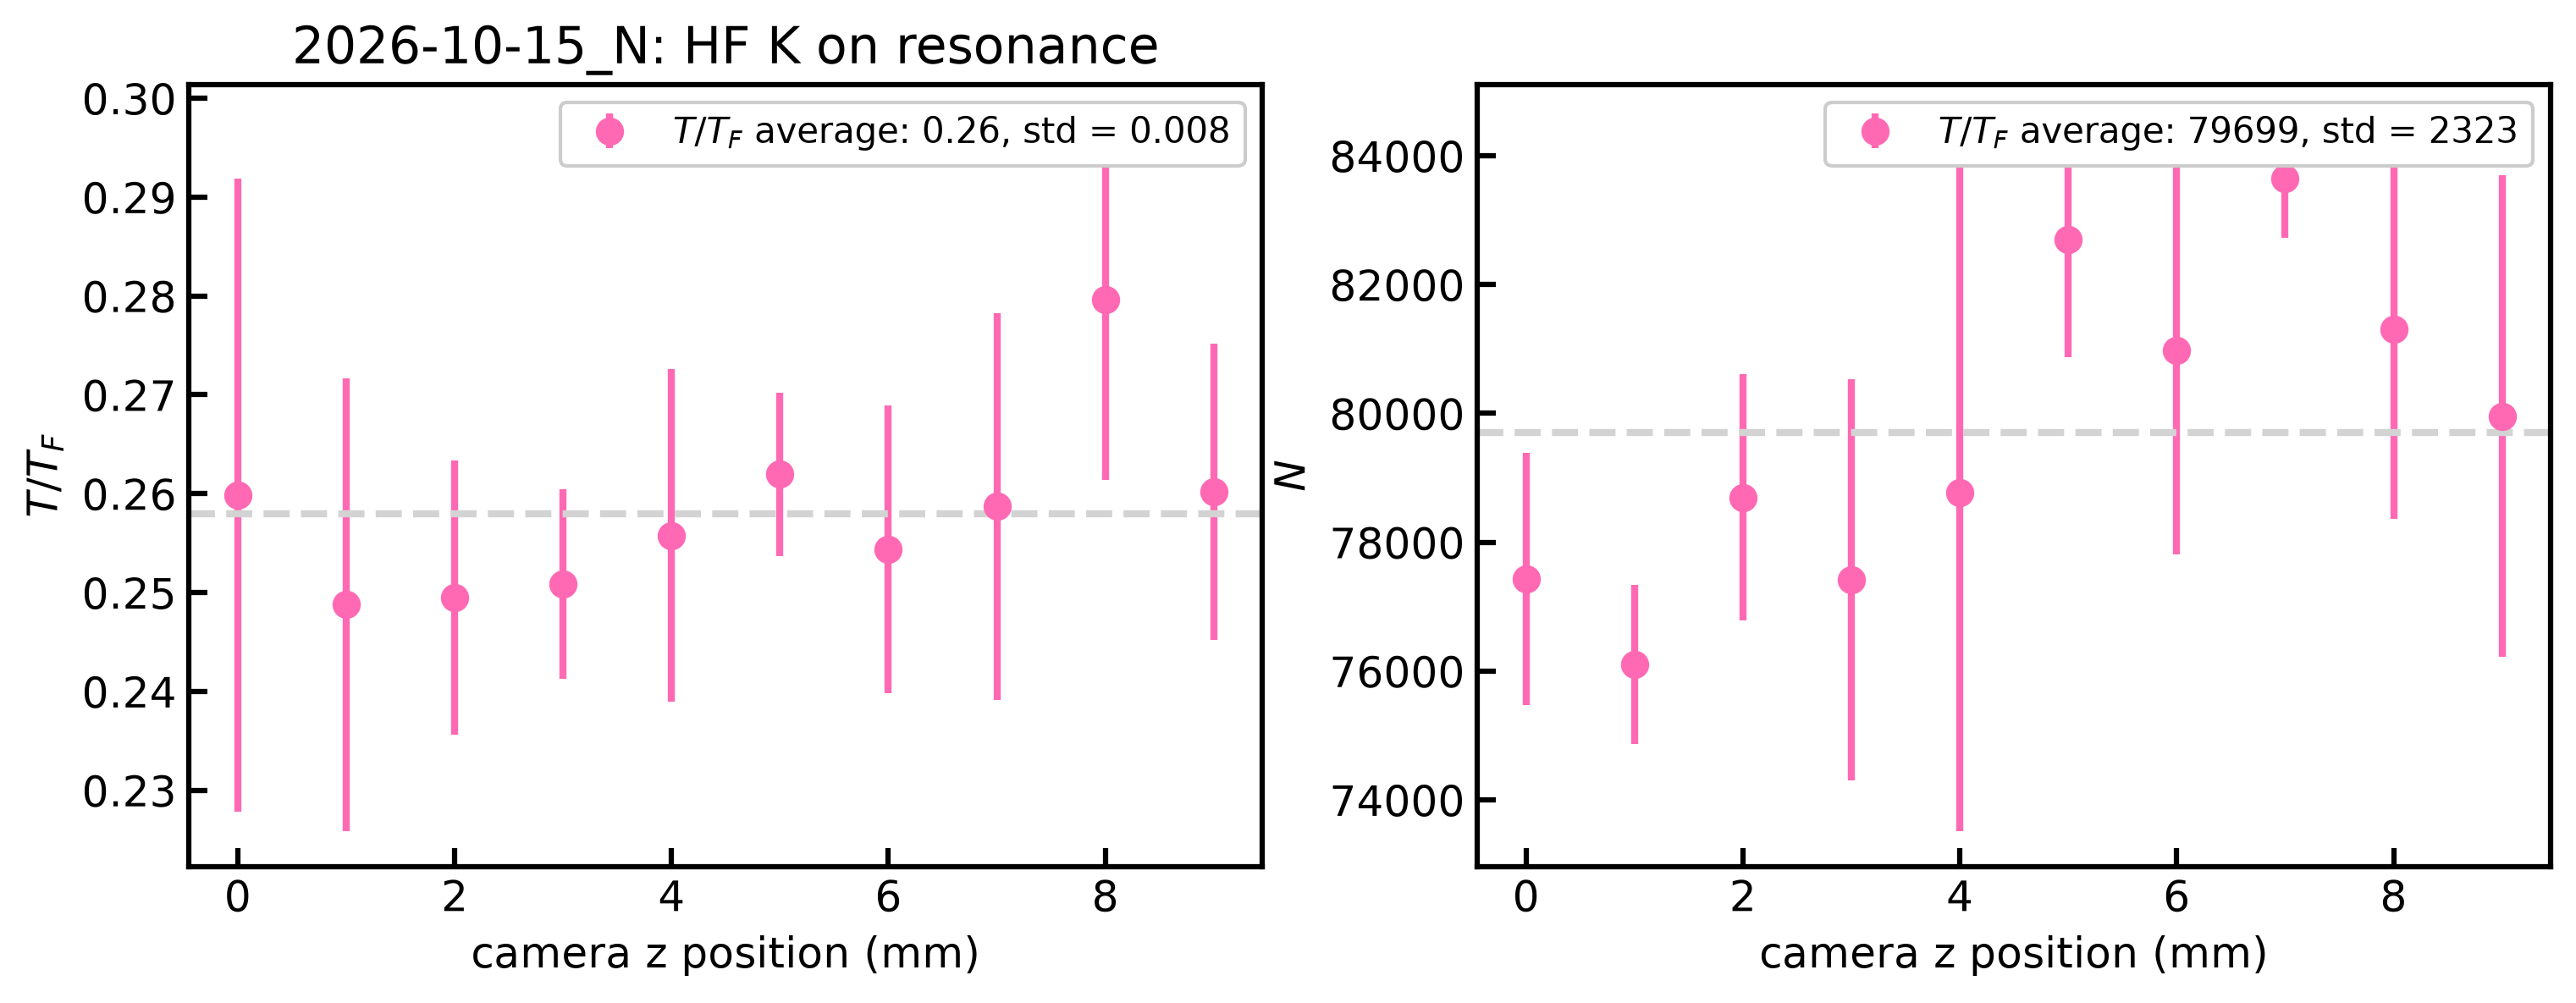

In [64]:
fig, axs = plt.subplots(1, 2, figsize=(12,4))
axs[0].errorbar(cam_pos, ToTF, eToTF, color="hotpink", label=f"$T/T_F$ average: {np.average(ToTF):.2f}, std = {np.std(ToTF):.3f}")
axs[0].axhline(np.average(ToTF), color="lightgrey", ls="--", marker="")
axs[0].set_ylabel(f"$T/T_F$")
axs[0].set_xlabel("camera z position (mm)")
axs[0].set_title("2026-10-15_N: HF K on resonance")

axs[0].legend()

axs[1].errorbar(cam_pos, N, eN, color="hotpink", label=f"$T/T_F$ average: {np.average(N):.0f}, std = {round(np.std(N))}")
axs[1].axhline(np.average(N), color="lightgrey", ls="--", marker="")
axs[1].set_ylabel(f"$N$")
axs[1].set_xlabel("camera z position (mm)")

axs[1].legend()

In [63]:
4000/80000

0.05